# Phase C: Hellinger fidelity and histograms (Deliverable 3)

Compares the distribution of the measured integer y for the ideal circuit (exact closed form, §4.3), the local emulation (Phase A) and IBM hardware (Phase B), for the configuration set below.

* **Hellinger fidelity** F = (Σ_y √(p_y q_y))²: 1 = identical, 0 = disjoint.
* **Peak mass**: probability on the integers nearest s·M/r.
* **Success rate**: fraction of shots that factor N after continued fractions.
* **Pure-noise floor**: the same metrics for a uniformly random y. Continued fractions forgive near misses, so the success floor is not 0. Judge hardware against the floor.

In [1]:
RUN_CORE_DEMO = False                  # load the core functions only, skip its demo/self-test cells
%run shor_core_generalized.ipynb

N, A = 15, 7                           # any odd composite N (not a prime power) and 1 < A < N, gcd(A, N) = 1
T = None                               # counting precision t; None = 2n
MODE = "semiclassical"                 # "semiclassical" = Beauregard 2n+3 qubits; "full" = t-qubit counting register

qc = build_shor_circuit(N, A, T, MODE, SKIP_IDENTITY)
t = qc.num_clbits
tag = run_tag(N, A, t, MODE)
print(f"{qc.name}: {qc.num_qubits} qubits, t = {t}")

shor_N15_a7_t8_semiclassical: 11 qubits, t = 8


In [2]:
import matplotlib.pyplot as plt
import numpy as np


def as_array(dist, t):
    total = sum(dist.values())
    arr = np.zeros(2 ** t)
    for bits, v in dist.items():
        arr[int(bits, 2)] = v / total
    return arr

## Load all runs

In [3]:
M = 2 ** t
ideal = exact_distribution(A, N, t)

runs = {"Ideal (exact)": ideal}     # label -> distribution
gates2q = {"Ideal (exact)": ""}     # label -> two-qubit gates after transpilation
for label, prefix in [("Local emulation", "local_counts"), ("IBM hardware", "ibm_counts")]:
    data = load_json(f"{prefix}_{tag}.json")
    if data is None:
        print(f"(skipping {label}: {results_path(f'{prefix}_{tag}.json')} not found)")
        continue
    key = f"{label} [{data['backend']}]"
    runs[key] = data["counts"]
    gates2q[key] = data.get("isa_stats", {}).get("two_qubit_gates", "")

(skipping Local emulation: results/local_counts_N15_a7_t8_semiclassical.json not found)


## Metrics table

In [4]:
peaks = peak_outcomes(A, N, t)
r = multiplicative_order(A, N)
uniform = {format(y, f"0{t}b"): 1.0 for y in range(M)}
print(f"N = {N}, a = {A}, r = {r}, t = {t}, mode = {MODE}; peaks at y = {peaks}")
print(f"Pure-noise floor: F = {hellinger_fidelity(ideal, uniform):.4f}, "
      f"peak mass = {len(peaks) / M:.4f}, success = {success_rate(uniform, t, A, N):.4f}\n")

print(f"{'run':<36}{'Hellinger F':>12}{'peak mass':>11}{'success':>9}{'2q gates':>10}")
fidelity = {}
for label, dist in runs.items():
    arr = as_array(dist, t)
    fidelity[label] = hellinger_fidelity(ideal, dist)
    print(f"{label:<36}{fidelity[label]:>12.4f}{arr[peaks].sum():>11.4f}"
          f"{success_rate(dist, t, A, N):>9.4f}{gates2q[label]:>10}")

try:   # cross-check against Qiskit's own implementation
    from qiskit.quantum_info import hellinger_fidelity as qiskit_hf
    for label, dist in runs.items():
        assert abs(qiskit_hf(ideal, dist) - fidelity[label]) < 1e-9
    print("\n(own Hellinger fidelity matches qiskit.quantum_info.hellinger_fidelity)")
except ImportError:
    pass

N = 15, a = 7, r = 4, t = 8, mode = semiclassical; peaks at y = [0, 64, 128, 192]
Pure-noise floor: F = 0.0156, peak mass = 0.0156, success = 0.2109

run                                  Hellinger F  peak mass  success  2q gates
Ideal (exact)                             1.0000     1.0000   0.5000          
IBM hardware [ibm_kingston]               0.9059     0.9065   0.4709      6401

(own Hellinger fidelity matches qiskit.quantum_info.hellinger_fidelity)


## Histograms

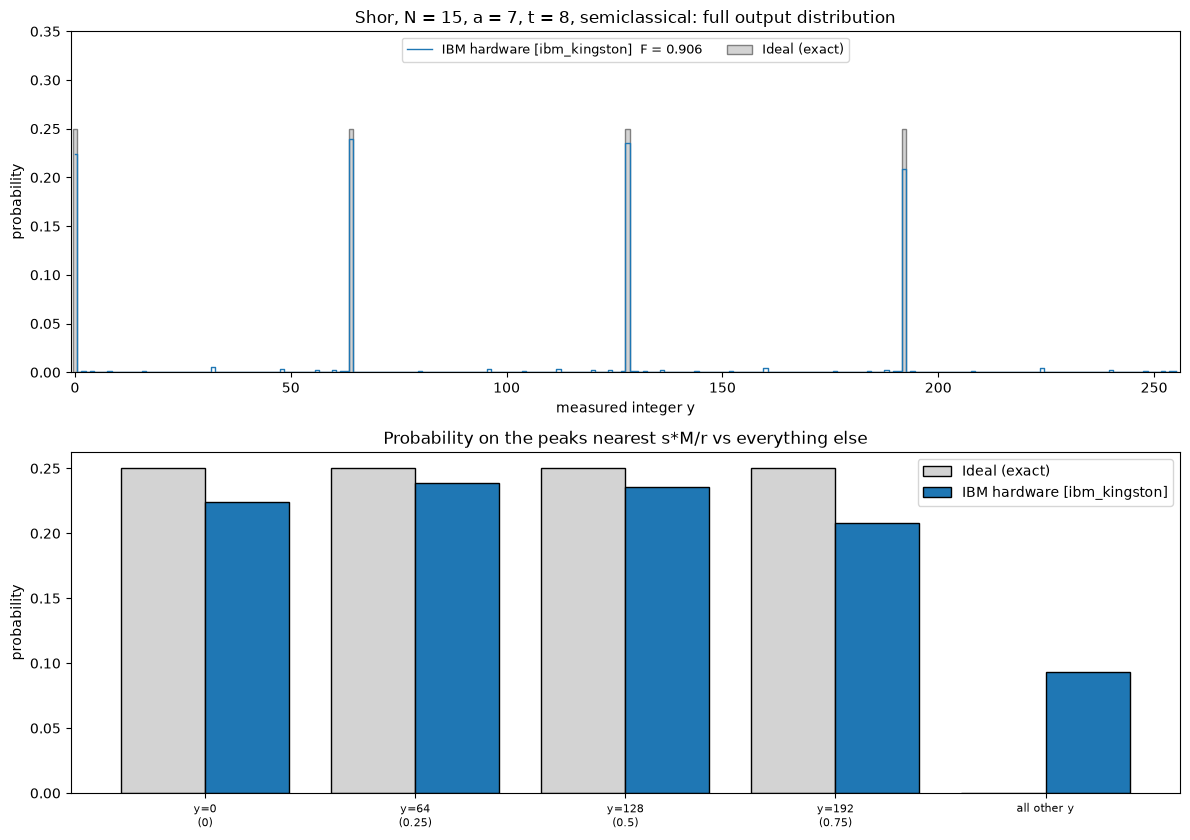

Saved results/comparison_N15_a7_t8_semiclassical.png


In [5]:
fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(12, 8.5))
x = np.arange(M)
colors = ["black", "tab:blue", "tab:red"]

for (label, dist), col in zip(runs.items(), colors):
    arr = as_array(dist, t)
    if label.startswith("Ideal"):
        ax_full.bar(x, arr, width=1.0, color="lightgray", edgecolor="gray", label=label)
    else:
        ax_full.step(x, arr, where="mid", color=col, lw=1, label=f"{label}  F = {fidelity[label]:.3f}")
ax_full.set_xlim(-1, M)
ax_full.set_ylim(0, 1.4 * max(ideal.values()))
ax_full.set_xlabel("measured integer y")
ax_full.set_ylabel("probability")
ax_full.set_title(f"Shor, N = {N}, a = {A}, t = {t}, {MODE}: full output distribution")
ax_full.legend(loc="upper center", ncol=3, fontsize=9)

ideal_arr = as_array(ideal, t)
shown = peaks if len(peaks) <= 12 else sorted(sorted(peaks, key=lambda p: -ideal_arr[p])[:12])
cats = [f"y={p}\n({p / M:.3g})" for p in shown] + ["all other y"]
width = 0.8 / len(runs)
for i, ((label, dist), col) in enumerate(zip(runs.items(), colors)):
    arr = as_array(dist, t)
    vals = list(arr[shown]) + [1 - arr[shown].sum()]
    pos = np.arange(len(cats)) + (i - (len(runs) - 1) / 2) * width
    ax_zoom.bar(pos, vals, width=width, color="lightgray" if label.startswith("Ideal") else col,
                edgecolor="black", label=label)
ax_zoom.set_xticks(np.arange(len(cats)))
ax_zoom.set_xticklabels(cats, fontsize=8)
ax_zoom.set_ylabel("probability")
ax_zoom.set_title("Probability on the peaks nearest s*M/r vs everything else")
ax_zoom.legend()

fig.tight_layout()
fig.savefig(results_path(f"comparison_{tag}.png"), dpi=150)
plt.show()
print(f"Saved {results_path(f'comparison_{tag}.png')}")